# Importing Required Libraries

### Download Climate Dataset

In [48]:
import kagglehub
import os
import pandas as pd

# 1. Download dataset via kagglehub
path = kagglehub.dataset_download("sumanthvrao/daily-climate-time-series-data")
print("Path to dataset files:", path)
print("Files available:", os.listdir(path))

# 2. Load the training weather dataset (Daily Delhi Climate Data)
csv_path = os.path.join(path, "DailyDelhiClimateTrain.csv")
df = pd.read_csv(csv_path)

print("\nDataFrame preview:")
display(df.head())

Using Colab cache for faster access to the 'daily-climate-time-series-data' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data
Files available: ['DailyDelhiClimateTrain.csv', 'DailyDelhiClimateTest.csv']

DataFrame preview:


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


### Exploring Daily Delhi Climate Dataset
We will examine the columns, properties, and temporal patterns of our active Delhi climate dataset.

In [49]:
# Show climate dataframe overview
print("Climate Data Columns:", df.columns.tolist())
print("Total climate records:", len(df))
display(df.describe())

Climate Data Columns: ['date', 'meantemp', 'humidity', 'wind_speed', 'meanpressure']
Total climate records: 1462


,meantemp,humidity,wind_speed,meanpressure
count,1462.000000,1462.000000,1462.000000,1462.000000
mean,25.495521,60.771702,6.802209,1011.104548
std,7.348103,16.769652,4.561602,180.231668
min,6.000000,13.428571,0.000000,-3.041667
25%,18.857143,50.375000,3.475000,1001.580357
50%,27.714286,62.625000,6.221667,1008.563492
75%,31.305804,72.218750,9.238235,1014.944901
max,38.714286,100.000000,42.220000,7679.333333


### Formatting and Cleaning Time Series Index
We set the 'date' field as our DatetimeIndex so that we can handle the temperature column as a continuous daily time-series.

In [50]:
# We already loaded 'df' containing DailyDelhiClimateTrain.csv
climate_df = df.copy()
climate_df['date'] = pd.to_datetime(climate_df['date'])
climate_df.set_index('date', inplace=True)

# Resample to daily average of mean temperature
data = climate_df[['meantemp']].resample('D').mean().interpolate()
data.rename(columns={'meantemp': 'Mean_Temp'}, inplace=True)

print("Continuous Time Series Data:")
display(data.head())

Continuous Time Series Data:


,Mean_Temp
date,
2013-01-01,10.000000
2013-01-02,7.400000
2013-01-03,7.166667
2013-01-04,8.666667
2013-01-05,6.000000


### Visualizing the Target Variable: Mean Daily Temperature

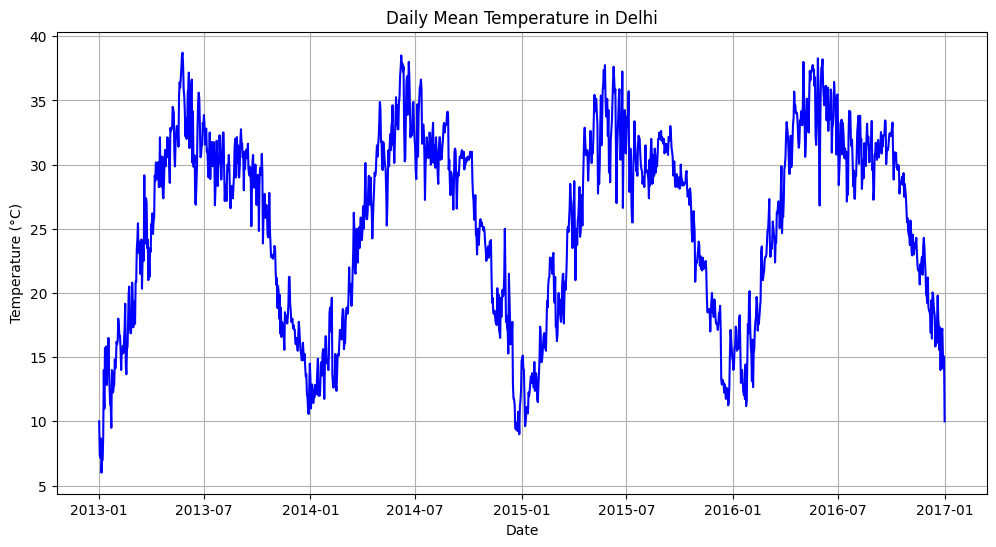

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(data['Mean_Temp'], color='blue')
plt.title('Daily Mean Temperature in Delhi')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

In [28]:
import pandas as pd
import numpy as np
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

### Target Temperature Verification
We verify that the data preparation is completed correctly before we pass it to the modeling phase.

In [52]:
print("Active Dataset is now Daily Delhi Climate (Mean Temperature)!")
print(data.head())

Active Dataset is now Daily Delhi Climate (Mean Temperature)!
            Mean_Temp
date                 
2013-01-01  10.000000
2013-01-02   7.400000
2013-01-03   7.166667
2013-01-04   8.666667
2013-01-05   6.000000


### Preparing the Train-Test Split

In [53]:
# We will train up to 2016-08-01 and use the remainder for out-of-sample validation
train = data[data.index < '2016-08-01']['Mean_Temp']
test = data[data.index >= '2016-08-01']['Mean_Temp']

print("Train length:", len(train))
print("Test length:", len(test))

Train length: 1308
Test length: 154


In [54]:
print("Verify train start/end:", train.index[0], "to", train.index[-1])
print("Verify test start/end:", test.index[0], "to", test.index[-1])

Verify train start/end: 2013-01-01 00:00:00 to 2016-07-31 00:00:00
Verify test start/end: 2016-08-01 00:00:00 to 2017-01-01 00:00:00


### Time Series Feature Analysis
Let us analyze the stationarity and characteristics of our temperature time series.

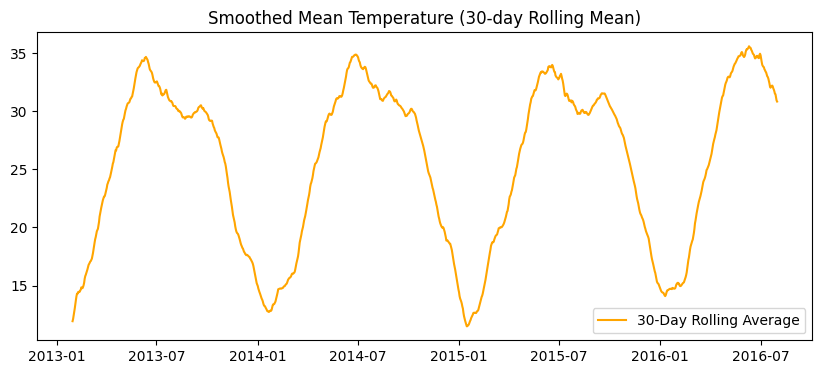

In [55]:
# Check if the time series shows a seasonal pattern (e.g. yearly peaks and troughs)
plt.figure(figsize=(10, 4))
plt.plot(train.rolling(window=30).mean(), color='orange', label='30-Day Rolling Average')
plt.legend()
plt.title('Smoothed Mean Temperature (30-day Rolling Mean)')
plt.show()

### Setting Up down-stream target mapping

In [56]:
# Maintaining compatibility with downstream variables by ensuring train and test are matched to Mean_Temp
train = data[data.index < '2016-08-01']['Mean_Temp']
test = data[data.index >= '2016-08-01']['Mean_Temp']

# Modeling

In [57]:
print("Training Observations:", len(train))
print("Testing Observations:", len(test))

Training Observations: 1308
Testing Observations: 154


In [58]:
print("Columns:", data.columns.tolist())
print("Index name:", data.index.name)
print("Index type:", type(data.index))
print("\nFirst 5 rows of Delhi Climate Dataset:")
print(data.head())

Columns: ['Mean_Temp']
Index name: date
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

First 5 rows of Delhi Climate Dataset:
            Mean_Temp
date                 
2013-01-01  10.000000
2013-01-02   7.400000
2013-01-03   7.166667
2013-01-04   8.666667
2013-01-05   6.000000


# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No.of lag can be defined manually  by seeing ACF plot. By default the algorithm shows the best lag.

In [59]:
# Keeping split consistent across all cells
train = data[data.index < '2016-08-01']['Mean_Temp']
test = data[data.index >= '2016-08-01']['Mean_Temp']
print("Split verified. Train length:", len(train), "| Test length:", len(test))

Split verified. Train length: 1308 | Test length: 154


In [60]:
lags = 12
model = AutoReg(train, lags=lags)
model_fit = model.fit()

In [61]:
# Get the coefficients (beta values) of the model
coefficients = model_fit.params

# Print the results
print(f"Lags considered statistically: {lags}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const            0.389874
Mean_Temp.L1     0.793029
Mean_Temp.L2     0.024945
Mean_Temp.L3    -0.040291
Mean_Temp.L4     0.109596
Mean_Temp.L5    -0.007308
Mean_Temp.L6     0.051595
Mean_Temp.L7    -0.021852
Mean_Temp.L8     0.028481
Mean_Temp.L9    -0.028441
Mean_Temp.L10    0.008210
Mean_Temp.L11    0.083035
Mean_Temp.L12   -0.015188
dtype: float64


The autoregressive coefficients represent the relationship between current daily temperatures and past lag values.

In [62]:
# Predicting the test values
predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

In [63]:
print('The first test value in Climate Dataset:', test.values[1], 'and its Predicted value:', predictions.values[1])

The first test value in Climate Dataset: 30.6875 and its Predicted value: 29.713337489299356


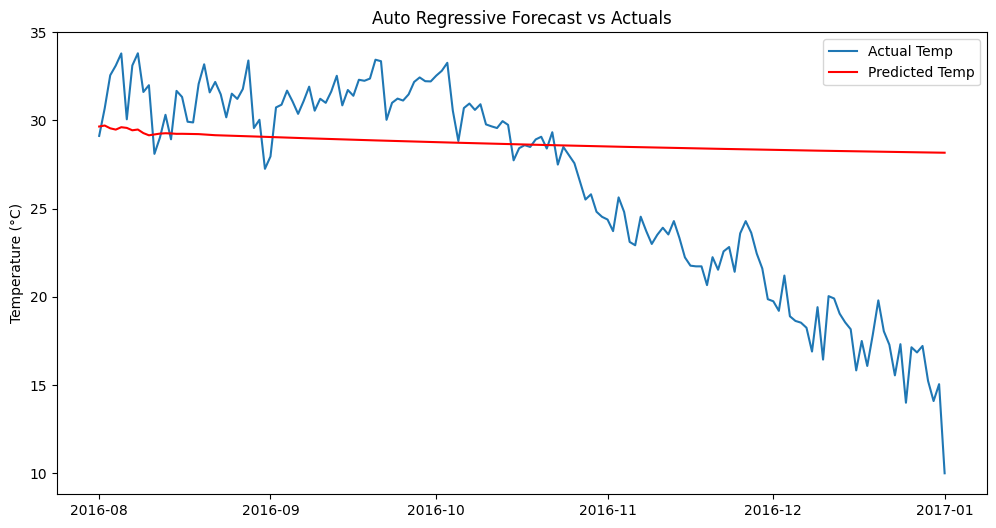

In [64]:
# plot results
plt.figure(figsize=(12,6))
plt.plot(test, label='Actual Temp')
plt.plot(predictions, color='red', label='Predicted Temp')
plt.title('Auto Regressive Forecast vs Actuals')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()

In [42]:
# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

In [65]:
# Mean Absolute Percentage Error
abs_error = np.abs(test - predictions)
actual = test
mape = np.round(np.mean(abs_error/actual),3)
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'RMSE': [rmse]})
mape

np.float64(0.223)

In [66]:
# Storing results in a dataframe
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'MAPE': [mape], 'RMSE': [rmse]})
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,6.503,0.223


# Model 2: Auto Regressive Integrated Moving Average(ARIMA)

The model involves specifying the order for the AR(p) and MA(q) model

Best ARIMA (6, 0) model - AIC:5014.28304038814
Order of AR part: 6
Coefficients: const     24.334432
ar.L1      0.799791
ar.L2      0.039106
ar.L3     -0.036250
ar.L4      0.108619
ar.L5      0.006689
ar.L6      0.069254
sigma2     2.666793
dtype: float64


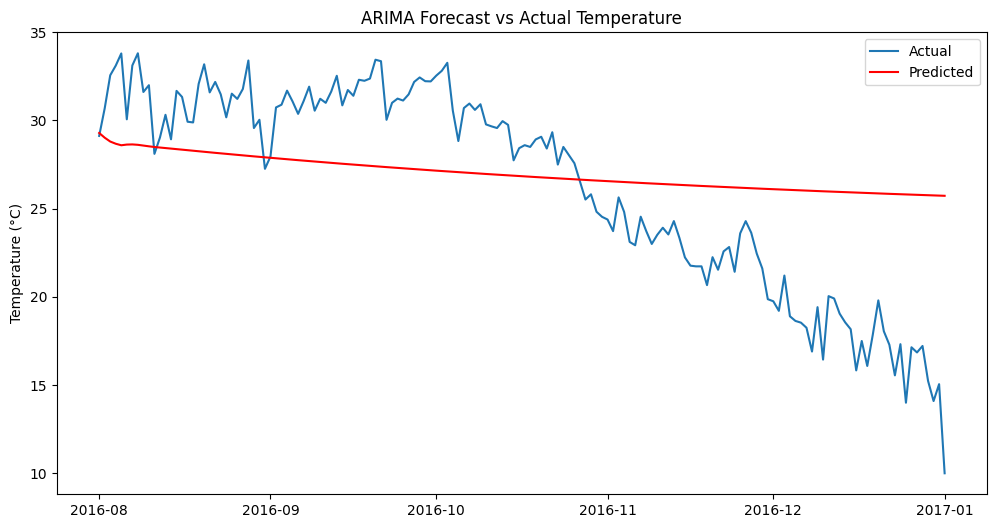

,Method,RMSE,MAPE
0,Auto Regressive,6.503,0.223
0,ARIMA,5.041,0.195


In [67]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Define parameters
p = range(0, 7)
q = range(0, 1)

# Generate all different combinations of p,q
pq = list(itertools.product(p, q))

best_aic = np.inf
best_pq = None
temp_model = None

for param in pq:
    try:
        temp_model = ARIMA(train, order=(param[0], 0, param[1]))
        results = temp_model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_pq = param
    except:
        continue

print("Best ARIMA {} model - AIC:{}".format(best_pq, best_aic))

# using the best parameter in the model
model = ARIMA(train, order=(best_pq[0], 0, best_pq[1]))
model_fit = model.fit()

# Print the order of the AR part of the model
print('Order of AR part: %s' % best_pq[0])
print('Coefficients: %s' % model_fit.params)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test, label='Actual')
plt.plot(predictions, color='red', label='Predicted')
plt.title('ARIMA Forecast vs Actual Temperature')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test-predictions)
actual = test
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['ARIMA'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
display(resultsDf)

# Model 2: Seasonal Auto Regressive Integrated Moving Average(SARIMA)

It combines the ARIMA model with the ability to perform the same autoregression, differencing, and moving average modeling at the seasonal level.

Best SARIMA (1, 1, 1) x (0, 0, 1, 12) model - AIC:4927.163436150958


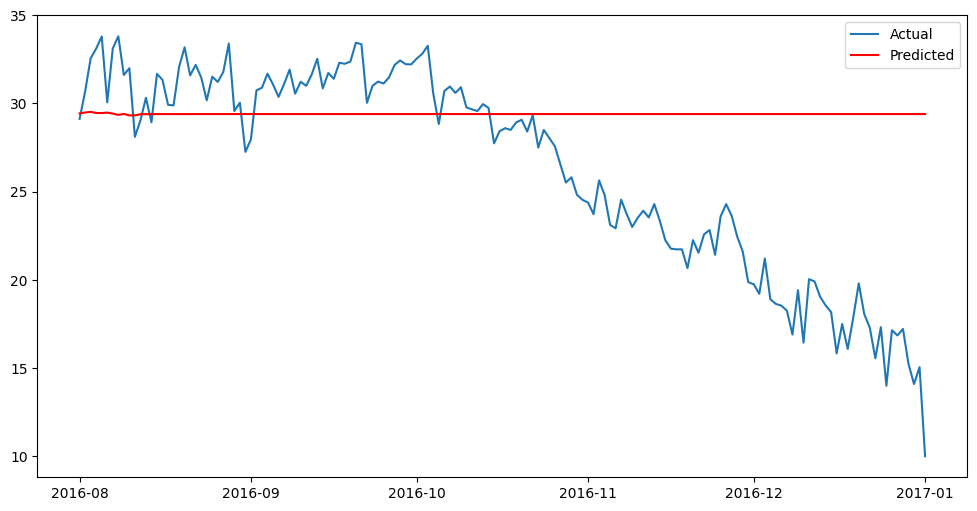

,Method,RMSE,MAPE
0,Auto Regressive,5.916,0.223
1,Auto Regressive Moving average,5.041,0.195
2,Seasonal Autoregressive Integrated Moving Average,6.503,0.243


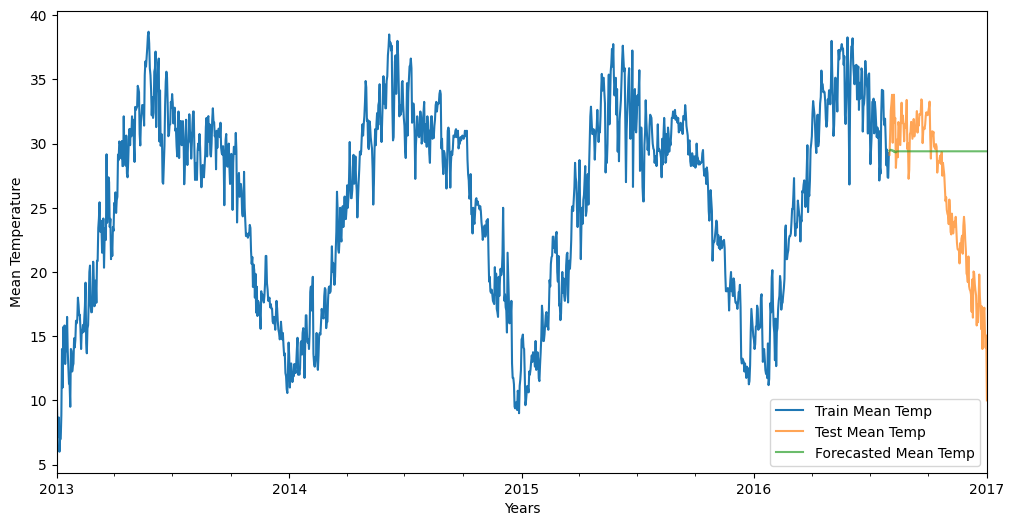

In [46]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, d and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, d and q triplets (using seasonal period 12)
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            temp_model = SARIMAX(train, order=param, seasonal_order=param_seasonal, enforce_invertibility=False, enforce_stationarity=False)
            results = temp_model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

print("Best SARIMA {} x {} model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))

# using the best parameter in the model
model = SARIMAX(train, order=best_pdq, seasonal_order=best_seasonal_pdq, enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit()

# Using date-based indices to guarantee alignment and prevent forecasting index errors
predictions = model_fit.predict(start=test.index[0], end=test.index[-1], dynamic=False)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test, label='Actual')
plt.plot(predictions, color='red', label='Predicted')
plt.legend()
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test-predictions)
actual = test
mape = np.round(np.mean(abs_error/(actual+1e-5)),3)

# Ensure resultsDf is defined before appending
try:
    resultsDf
except NameError:
    resultsDf = pd.DataFrame(columns=['Method', 'RMSE', 'MAPE'])

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Seasonal Autoregressive Integrated Moving Average'], 'RMSE': [rmse],'MAPE': [mape] })
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf.index = [i for i in range(len(resultsDf))]
display(resultsDf)

# Plotting the train, test and forecasted values
axis = train.plot(label='Train Mean Temp', figsize=(12, 6))
test.plot(ax=axis, label='Test Mean Temp', alpha=0.7)
predictions.plot(ax=axis, label='Forecasted Mean Temp', alpha=0.7)
axis.set_xlabel('Years')
axis.set_ylabel('Mean Temperature')
plt.legend(loc='best')
plt.show()
plt.close()

In [47]:
# Storing results in a dataframe

print(resultsDf)

                                              Method   RMSE   MAPE
0                                    Auto Regressive  5.916  0.223
1                    Auto Regressive Moving average   5.041  0.195
2  Seasonal Autoregressive Integrated Moving Average  6.503  0.243
